In [ ]:
#import libraries
import pandas as pd
import numpy as np
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error,mean_squared_error, r2_score
import matplotlib.pyplot as plt
import seaborn as sns

In [ ]:
#load the dataset
df=pd.read_csv('/content/cardata.csv')
df.head()

,Car_Name,Year,Selling_Price,Present_Price,Kms_Driven,Fuel_Type,Seller_Type,Transmission,Owner
0,ritz,2014,3.35,5.59,27000,Petrol,Dealer,Manual,0
1,sx4,2013,4.75,9.54,43000,Diesel,Dealer,Manual,0
2,ciaz,2017,7.25,9.85,6900,Petrol,Dealer,Manual,0
3,wagon r,2011,2.85,4.15,5200,Petrol,Dealer,Manual,0
4,swift,2014,4.60,6.87,42450,Diesel,Dealer,Manual,0


In [ ]:
df.shape

(301, 9)

In [ ]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 301 entries, 0 to 300
Data columns (total 9 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   Car_Name       301 non-null    object 
 1   Year           301 non-null    int64  
 2   Selling_Price  301 non-null    float64
 3   Present_Price  301 non-null    float64
 4   Kms_Driven     301 non-null    int64  
 5   Fuel_Type      301 non-null    object 
 6   Seller_Type    301 non-null    object 
 7   Transmission   301 non-null    object 
 8   Owner          301 non-null    int64  
dtypes: float64(2), int64(3), object(4)
memory usage: 21.3+ KB


In [ ]:
df.describe()

,Year,Selling_Price,Present_Price,Kms_Driven,Owner
count,301.000000,301.000000,301.000000,301.000000,301.000000
mean,2013.627907,4.661296,7.628472,36947.205980,0.043189
std,2.891554,5.082812,8.644115,38886.883882,0.247915
min,2003.000000,0.100000,0.320000,500.000000,0.000000
25%,2012.000000,0.900000,1.200000,15000.000000,0.000000
50%,2014.000000,3.600000,6.400000,32000.000000,0.000000
75%,2016.000000,6.000000,9.900000,48767.000000,0.000000
max,2018.000000,35.000000,92.600000,500000.000000,3.000000


In [ ]:
df.isnull().sum()

,0
Car_Name,0
Year,0
Selling_Price,0
Present_Price,0
Kms_Driven,0
Fuel_Type,0
Seller_Type,0
Transmission,0
Owner,0


In [ ]:
#count occurance of each Fuel_type in the dataset
df['Fuel_Type'].value_counts()

,count
Fuel_Type,
Petrol,239
Diesel,60
CNG,2


In [ ]:
#count occurance of each Seller_type in the dataset
df['Seller_Type'].value_counts()

,count
Seller_Type,
Dealer,195
Individual,106


In [ ]:
#count occurances of each transmission type in the dataset
df['Transmission'].value_counts()

,count
Transmission,
Manual,261
Automatic,40


In [ ]:
#One-hot encoding
df=pd.get_dummies(df,columns=['Fuel_Type','Seller_Type','Transmission'])
df.head()

,Car_Name,Year,Selling_Price,Present_Price,Kms_Driven,Owner,Fuel_Type_CNG,Fuel_Type_Diesel,Fuel_Type_Petrol,Seller_Type_Dealer,Seller_Type_Individual,Transmission_Automatic,Transmission_Manual
0,ritz,2014,3.35,5.59,27000,0,False,False,True,True,False,False,True
1,sx4,2013,4.75,9.54,43000,0,False,True,False,True,False,False,True
2,ciaz,2017,7.25,9.85,6900,0,False,False,True,True,False,False,True
3,wagon r,2011,2.85,4.15,5200,0,False,False,True,True,False,False,True
4,swift,2014,4.60,6.87,42450,0,False,True,False,True,False,False,True


In [ ]:
df.columns

Index(['Car_Name', 'Year', 'Selling_Price', 'Present_Price', 'Kms_Driven',
       'Owner', 'Fuel_Type_CNG', 'Fuel_Type_Diesel', 'Fuel_Type_Petrol',
       'Seller_Type_Dealer', 'Seller_Type_Individual',
       'Transmission_Automatic', 'Transmission_Manual'],
      dtype='object')

In [ ]:
x=df.drop(['Car_Name','Selling_Price'],axis=1, errors='ignore')
print("Feature matrix X created by dropping 'car_name' and 'selling_price' columns")

Feature matrix X created by dropping 'car_name' and 'selling_price' columns


In [ ]:
y=df['Selling_Price']
print("Target variable y created by selecting 'selling_price' column")

Target variable y created by selecting 'selling_price' column


In [ ]:
df.head()

,Year,Selling_Price,Present_Price,Kms_Driven,Owner,Fuel_Type_CNG,Fuel_Type_Diesel,Fuel_Type_Petrol,Seller_Type_Dealer,Seller_Type_Individual,Transmission_Automatic,Transmission_Manual
0,2014,3.35,5.59,27000,0,False,False,True,True,False,False,True
1,2013,4.75,9.54,43000,0,False,True,False,True,False,False,True
2,2017,7.25,9.85,6900,0,False,False,True,True,False,False,True
3,2011,2.85,4.15,5200,0,False,False,True,True,False,False,True
4,2014,4.60,6.87,42450,0,False,True,False,True,False,False,True


In [ ]:
#split the dataset into training and testing
x_train,x_test,y_train,y_test=train_test_split(x,y,test_size=0.2,random_state=42)
print("Dataset split into training and testing sets")

Dataset split into training and testing sets


In [ ]:
#create the model
model=LinearRegression()
print("Linear regression model created")

Linear regression model created


In [ ]:
#train the model
model.fit(x_train,y_train)
print("Model trained on the training data")

Model trained on the training data


In [ ]:
#Generate predictions for training and testing data
y_train_pred=model.predict(x_train)
y_test_pred=model.predict(x_test)
print("Predictions generated for training and testing data")

Predictions generated for training and testing data


In [ ]:
#Evaluate the model performance on training data using metrics
print("Model performance evaluation on training data")
mae_train=mean_absolute_error(y_train,y_train_pred)
print("Mean Absolute Error (MAE):",mae_train)
mse_train=mean_squared_error(y_train,y_train_pred)
print("Mean Squared Error (MSE):",mse_train)
r2_train=r2_score(y_train,y_train_pred)
print("R-squared (R2) Score:",r2_train)

Model performance evaluation on training data
Mean Absolute Error (MAE): 1.1675804448342353
Mean Squared Error (MSE): 2.9437205399630173
R-squared (R2) Score: 0.8886517300804558


In [ ]:
#Evaluate the model performance on testing data using metrics
print("Model performance evaluation on testing data")
mae_test=mean_absolute_error(y_test,y_test_pred)
print("Mean Absolute Error (MAE):",mae_test)
mse_test=mean_squared_error(y_test,y_test_pred)
print("Mean Squared Error (MSE):",mse_test)
r2_test=r2_score(y_test,y_test_pred)
print("R-squared (R2) Score:",r2_test)

Model performance evaluation on testing data
Mean Absolute Error (MAE): 1.216225682130144
Mean Squared Error (MSE): 3.4788039706448317
R-squared (R2) Score: 0.8489813024896058


In [ ]:
#coefficients and Intercept
coefficients=model.coef_
print("Coefficients:",coefficients)
intercept=model.intercept_
print("Intercept:",intercept)

Coefficients: [ 3.53801365e-01  4.29152503e-01 -6.15725866e-06 -9.03759824e-01
 -1.09057894e+00  1.44269365e+00 -3.52114710e-01  5.95296453e-01
 -5.95296453e-01  8.19510777e-01 -8.19510777e-01]
Intercept: -710.2771513359723


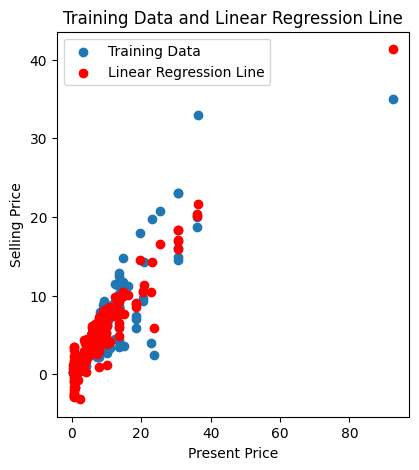

In [ ]:
#Visualization(training variable and residual)
plt.figure(figsize=(10,5))
plt.subplot(1,2,1)
plt.scatter(x_train['Present_Price'],y_train,label='Training Data')
plt.scatter(x_train['Present_Price'],y_train_pred,label='Linear Regression Line',color='red')
plt.xlabel('Present Price')
plt.ylabel('Selling Price')
plt.title('Training Data and Linear Regression Line')
plt.legend()